# Connectome Spectrum Transform from a template

If the patient's tractography is unavailable, you can infer a structural connectome using a connectome atlas. In this project, we use the MultiConn atlas from [Alemán-Gómez et. al 2022](https://www.nature.com/articles/s41597-022-01624-8).

The connectome in this context represents the structural connections between sources in our source space. These include white matter tracts (long-range connections) inferred from an atlas, and gray matter tracts (short-range connections) inferred from a specific method.

- **White Matter Tracts**: Two sources are connected if the brain regions they belong to are connected according to the MultiConn atlas. This requires segmenting the subject's brain using MultiConn's parcellation, which was done in `./parcellation.ipynb`. The parcellation results are stored in `../dataset/spike_sample/derivatives/mindmap/subject/parc/`.
- **Gray Matter Tracts**: Two sources are connected if their geodesic distance is smaller than a user-defined threshold.

Once the connectome for the source space is obtained, the Connectome Spectrum Transform is performed by computing the graph signal transform of the connectome.

# Batch Wise Run

Run the code for all subjects of a given dataset.

## 📦 Imports

In [1]:
import mindmap as mm
from pathlib import Path
import numpy as np

## 🧠 Data

In [2]:
# configuration
config   = mm.io.read_config("../configurations/spike.yml")
subjects = config["SUBS"]
mm_dir   = Path(config["MM_DIR"])

# options
overwrite = True 
save_sc   = True

# parameters
consistency_thr = 40
length_thr = 25
number_thr = 20
distance_thr = 0.010

# file naming
fsc  = lambda sub: mm_dir/sub/"cst"/f"{sub}_sc-template.npy"
fcst = lambda sub: mm_dir/sub/"cst"/f"{sub}_cst-template.npy"

## ♾️ Loop

In [3]:
for sub in subjects:
    # check file existence 
    sc_fname  = fsc(sub)
    cst_fname = fcst(sub)

    exists = mm.utils.files_exists([sc_fname, cst_fname], mkdir=True)
    if any(exists) and not overwrite:
        print(f"Subject {sub} already has one of the files to generate.")
        continue

    # Generate CST
    try:
        cst, sc = mm.utils.create_cst_from_template(sub, consistency_thr, length_thr, number_thr, distance_thr)
    except Exception as e:
        print(f"\033[91mFailed to generate CST for subject {sub} due to: {e}\033[0m")
        continue

    # save
    np.save(sc_fname, sc.todense())
    np.save(cst_fname, cst)

    print(f"\033[92mSuccessfully computed CST for subject '{sub}'\033[0m")

Failed to generate CST for subject sub-pat01 due to: File does not exist: "/media/nino/DATA/SPIKE/derivatives/mindmap/sub-pat01/fwd/sub-pat01_fwd.fif"
DATA SUMMARY
Dataset: spike
Subject: sub-pat02
Retrieved objects:
- src
- parc
Missing objects:


2025-03-24 16:37:11,742:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (6004 x 6004) may take some time.


Successfully computed CST for subject 'sub-pat02'
DATA SUMMARY
Dataset: spike
Subject: sub-pat03
Retrieved objects:
- src
- parc
Missing objects:


2025-03-24 16:37:28,900:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (5904 x 5904) may take some time.


Successfully computed CST for subject 'sub-pat03'
DATA SUMMARY
Dataset: spike
Subject: sub-pat04
Retrieved objects:
- src
- parc
Missing objects:


2025-03-24 16:37:42,648:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (5360 x 5360) may take some time.


... (77 outputs left out)

2025-03-24 16:51:05,958:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (6855 x 6855) may take some time.


Successfully computed CST for subject 'sub-pat44'
DATA SUMMARY
Dataset: spike
Subject: sub-pat45
Retrieved objects:
- src
- parc
Missing objects:


2025-03-24 16:51:38,279:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (6745 x 6745) may take some time.


Successfully computed CST for subject 'sub-pat45'


# Step Wise Run

Run the code step by step for a single subject.

## 📦 Imports

In [1]:
from pathlib import Path
import os

import mindmap as mm

import numpy as np
import scipy as sp
import pandas as pd
import pygsp

import matplotlib.pyplot as plt 

## 🧠 Data

In [9]:
env = mm.io.read_config("../configurations/spike.yml")
sub = env["SUBS"][10]

# directories
mm_dir = Path(os.environ["MM_DIR"])

# data
data = mm.io.read_dataset(sub, "src", "parc", "white", "cras")
std  = mm.io.read_standards("conn")

# parameters
cons_thresh = 40       # consistency threshold
len_thresh  = 25       # fiber length threshold
n_thresh    = 20       # number of streamlines threshold
dmax        = 0.010    # maximum distance for short distance connection

DATA SUMMARY
Dataset: spike
Subject: sub-pat11
Retrieved objects:
- cras
- white
- src
- parc
Missing objects:


#### Additional utility

In [10]:
def correct_labels(labels, sources, parcel):
    """
    Correct labels that misplace left and right hemisphere dipoles because the parcellation is not perfect.
    """
    # map to switch from label id to label name
    clut = parcel.get_clut()
    map  = pd.Series(clut["Label name"].values, index=clut["#No."]).to_dict()
    
    label_names = [map[id] for id in labels]

    # left/right hemisphere seperation
    split = len(sources[0]["vertno"])

    # switch 'lh' labels in right hemisphere to 'rh' homologue and vice virsa
    label_names[:split] = [l.replace("-rh-", "-lh-") for l in label_names[:split]]
    label_names[split:] = [l.replace("-lh-", "-rh-") for l in label_names[split:]]

    # convert back to lable ids
    new_labels = [list(map.keys())[list(map.values()).index(n)] for n in label_names]

    return new_labels

## Infere Subject Connectome from Atlas Connectome
⚙️ <font color=green>**Threshold Atlas**</font>: First we threshold the atlas to our liking. Threshold values were chosen to produce the cleanest harmonics.

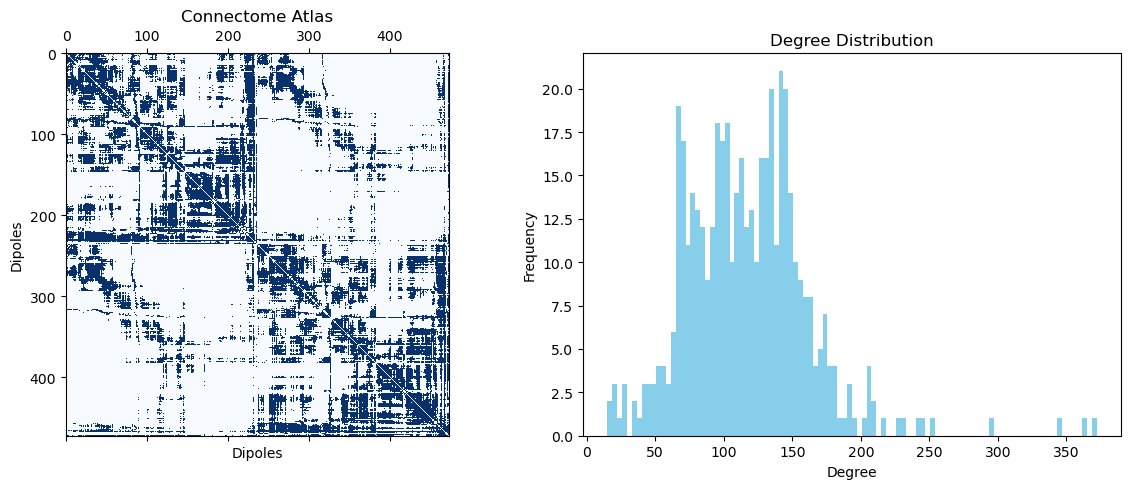

In [11]:
# label sources
pos    = mm.utils.get_src_position(data["src"])
pos    = pos*1000 + data["cras"]                   # in surface RAS space in [mm].  !!!!!!! Add the cras translation now that I now  !!!!!!!
labels = data["parc"].label_points(pos, id=True)   # brain region label for each source.

# some left/right regions are very close and get mixed up
labels = mm.utils.correct_labels(labels, data["src"], data["parc"])

# convert atlas to binary adjacency matrix
consistency = std["conn"]["matrices"]["consistency"]
length      = std["conn"]["matrices"]["length"]
number      = std["conn"]["matrices"]["numbStlines"]

sc_atlas = np.bitwise_and(
    consistency[:,:] > cons_thresh, 
    length[:,:] > len_thresh,
    number[:,:] > n_thresh,
)

mm.viz.plot_connectome(sc_atlas, name="Connectome Atlas")

⚙️ <font color=green>**Infer White Matter Tracks from Atlas**</font>: Create connections between sources as follows: let $i$ be a source in region A and $j$ be a source in region B. If the atlas indicates that region A is connected to region B, then connect $i$ to $j$.

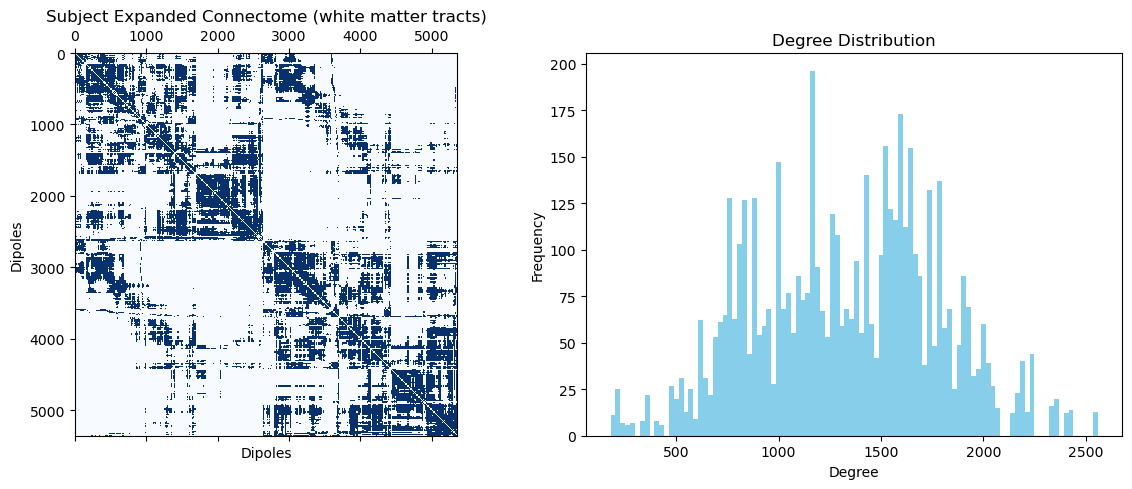

In [7]:
N = pos.shape[0]
sc = np.zeros((N,N))

for i, l in enumerate(labels):
    connected_regions = np.argwhere(sc_atlas[l-1]==1)+1
    connections = np.isin(labels, connected_regions)
    sc[i] = connections 

sc = sp.sparse.csc_array(sc>0)

# sort for plotting
idx = np.argsort(labels)
viz = sc.todense()[idx]
viz = viz[:,idx]
mm.viz.plot_connectome(viz, name="Subject Expanded Connectome (white matter tracts)")

⚙️ <font color=green>**Infer Gray Matter Tracks from Distance**</font>: If sources $i$ and $j$ are less than dmax distance apart, then connect $i$ and $j$.

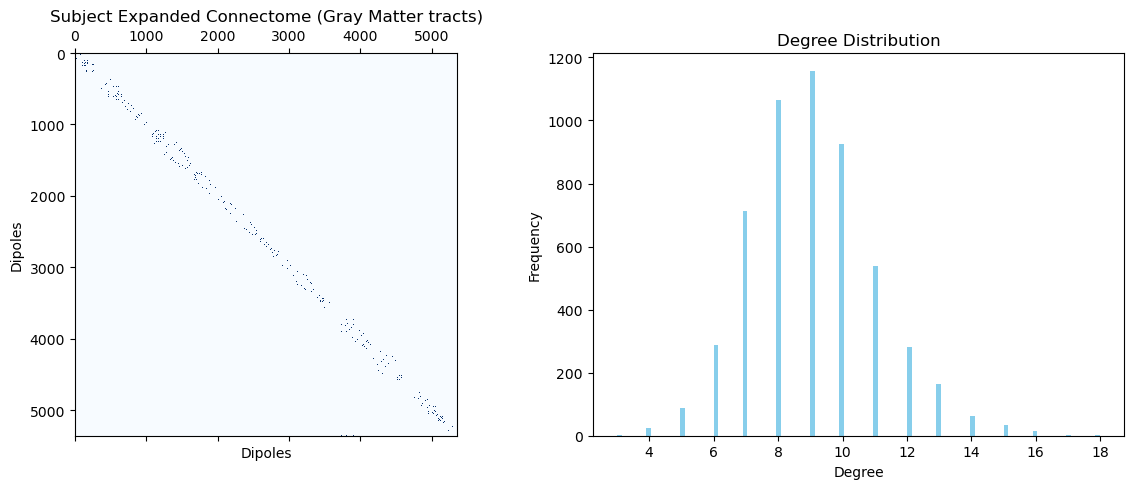

In [9]:
gmt = mm.utils.interpol_gm_tracks(data["src"], dmax)
mm.viz.plot_connectome(gmt.todense(), "Subject Expanded Connectome (Gray Matter tracts)")

⚙️ <font color=green>**Combine White Matter Tracks and Gray Matter Tracks**</font>

In [10]:
sc = sc + gmt 
sc = sc.astype(bool).astype(int)

#### <font color=yellow>🌟</font> Visualize Final Connectome

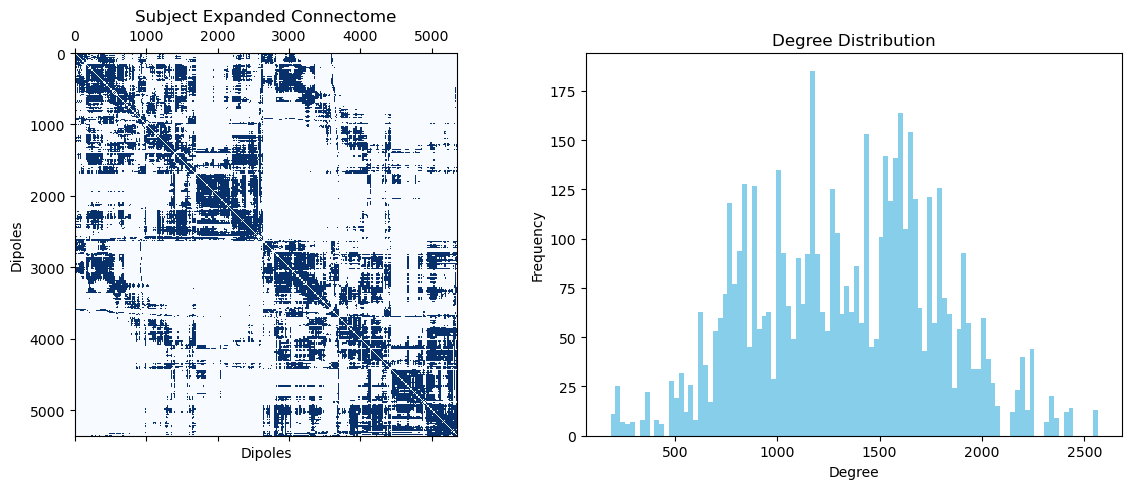

In [11]:
idx = np.argsort(labels)
viz = sc.todense()[idx]
viz = viz[:,idx]
mm.viz.plot_connectome(viz, "Subject Expanded Connectome")

## Connectome Spectrum Transform

⚙️ <font color=green>**Compute the Connectome Spectrum Transform (CST)**</font>: The CST is simply the Fourier Graph Transform of the connectome. The harmonics (or eigenvectors) of this transform are characteristic of the connectome. Visualize them to assess the quality of the CST.

In [12]:
coords = [s["rr"][s["vertno"]] for s in data["src"]]
G = pygsp.graphs.Graph(sc.todense(), lap_type="normalized", coords=coords)
G.compute_fourier_basis()
cst = G.U.T

2025-03-24 15:32:30,210:[WARNING](pygsp.graphs.graph.compute_fourier_basis): Computing the full eigendecomposition of a large matrix (5360 x 5360) may take some time.


#### <font color=yellow>🌟</font> Visualize the harmonics

In [13]:
harmonic = cst[1,:]

max_abs = np.max(np.abs(harmonic))
mm.viz.plot_brain_signal(data["src"], harmonic, clim=[-max_abs, max_abs]).show()

Widget(value='<iframe src="http://localhost:38993/index.html?ui=P_0x7130fb7c97f0_0&reconnect=auto" class="pyvi…

## 💾 Save the SC
🚨 The structural connectome (SC) is not needed for source reconstruction. Save only if needed for personal use.

In [13]:
folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving SC from template for subject: {sub}")
np.save(folder/f"{sub}_sc-hr-template.npy", sc.todense())

Saving SC from template for subject: vepcon_sub-10


## 💾 Save the CST

In [14]:
folder = mm_dir/sub/"sc"
if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving CST from template for subject: {sub}")
np.save(folder/f"{sub}_cst-hr-template.npy", cst)

Saving CST from template for subject: vepcon_sub-10
